## 1. Import Library

In [1]:
import pandas as pd
import numpy as np
import re, json, pickle, time, warnings
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from scipy.sparse import hstack, csr_matrix
from imblearn.over_sampling import SMOTE

# Install imbalanced-learn jika belum ada
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', 'imbalanced-learn', '-q'])

print("✓ Library siap")


✓ Library siap


In [22]:
!pip install pipreqs
!python -m pipreqs.pipreqs . --force --scan-notebooks

Defaulting to user installation because normal site-packages is not writeable


Please, verify manually the final list of requirements.txt to avoid possible dependency confusions.
Please, verify manually the final list of requirements.txt to avoid possible dependency confusions.
Please, verify manually the final list of requirements.txt to avoid possible dependency confusions.
Please, verify manually the final list of requirements.txt to avoid possible dependency confusions.
Please, verify manually the final list of requirements.txt to avoid possible dependency confusions.
Please, verify manually the final list of requirements.txt to avoid possible dependency confusions.
Please, verify manually the final list of requirements.txt to avoid possible dependency confusions.
INFO: Successfully saved requirements file in .\requirements.txt


In [3]:
df = pd.read_csv('dataset_tokopedia.csv')

print(f"Total sampel  : {len(df):,}")
print(f"Kolom         : {list(df.columns)}")
print(f"\nDistribusi Sentimen:")
print(df['sentiment'].value_counts())
print(f"\nDistribusi Rating:")
print(df['rating'].value_counts().sort_index())
print(f"\nRentang Tanggal: {df['date'].min()} s/d {df['date'].max()}")
df.head()


Total sampel  : 8,447
Kolom         : ['review_id', 'username', 'review', 'rating', 'thumbs_up', 'date', 'app_version', 'sentiment']

Distribusi Sentimen:
sentiment
negatif    4395
positif    3498
netral      554
Name: count, dtype: int64

Distribusi Rating:
rating
1    3832
2     563
3     554
4     448
5    3050
Name: count, dtype: int64

Rentang Tanggal: 2025-10-09 s/d 2026-02-27


,review_id,username,review,rating,thumbs_up,date,app_version,sentiment
0,6a040b9d-b66a-4964-98df-6abb19c93d0a,Vanto,belanja simple tidak ribet dan barang di pasti...,5,0,2026-02-27,3.352.2,positif
1,7fd77c8e-ad97-40cb-8944-afbdffbf081e,Ozog,Tokopedia cs tidak membantu permasalahan,1,0,2026-02-27,3.348.0,negatif
2,a4c165dd-225a-4ea1-b102-4b5410f7ebd4,Akmal Hadi,bagus.,5,0,2026-02-27,3.347.0,positif
3,42ef3f46-cf5a-40ae-afd3-4d183bdb7b29,Indira Ayu,sudah ga mampu kasih gratis ongkir parah,1,0,2026-02-27,3.353.0,negatif
4,e488c21e-e9de-4ff2-ad86-c59170b0c355,Fazza Figo,suka banget akuu,5,0,2026-02-27,3.352.2,positif


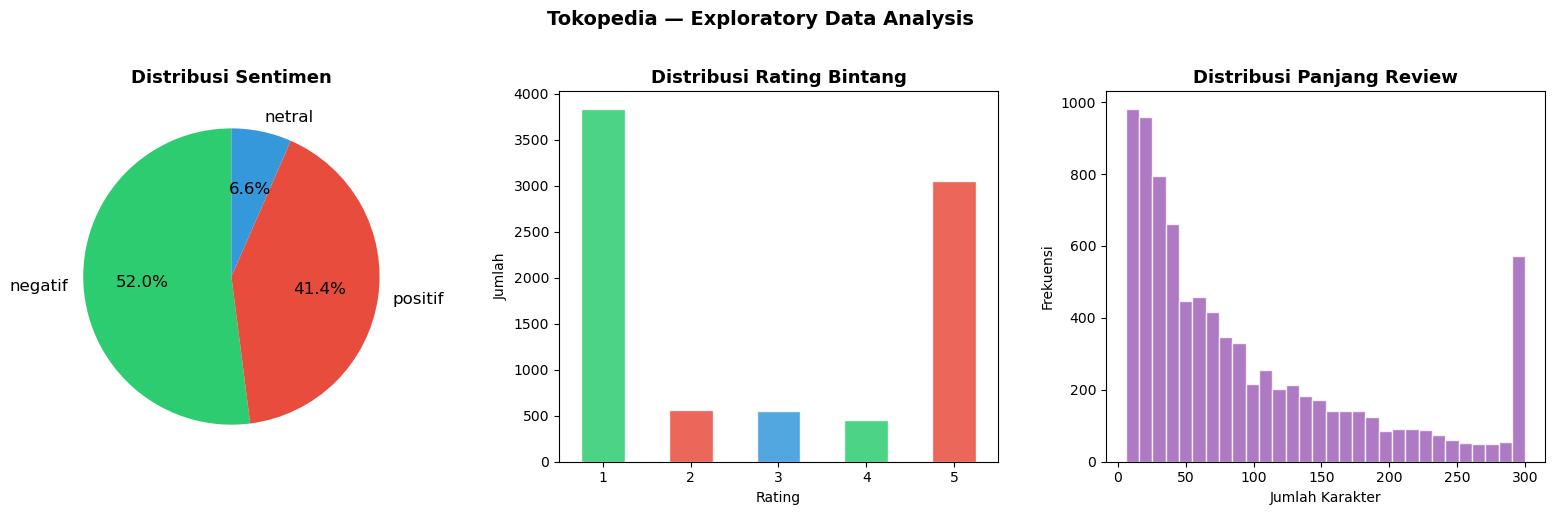

Rata-rata panjang review: 101 karakter


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

colors = ['#2ecc71', '#e74c3c', '#3498db']
counts = df['sentiment'].value_counts()

axes[0].pie(counts, labels=counts.index, autopct='%1.1f%%',
            colors=colors, startangle=90, textprops={'fontsize':12})
axes[0].set_title('Distribusi Sentimen', fontweight='bold', fontsize=13)

df['rating'].value_counts().sort_index().plot(
    kind='bar', ax=axes[1], color=colors*2, alpha=0.85, edgecolor='white')
axes[1].set_title('Distribusi Rating Bintang', fontweight='bold', fontsize=13)
axes[1].set_xlabel('Rating'); axes[1].set_ylabel('Jumlah')
axes[1].tick_params(axis='x', rotation=0)

df['panjang'] = df['review'].str.len()
axes[2].hist(df['panjang'].clip(0, 300), bins=30, color='#9b59b6', alpha=0.8, edgecolor='white')
axes[2].set_title('Distribusi Panjang Review', fontweight='bold', fontsize=13)
axes[2].set_xlabel('Jumlah Karakter'); axes[2].set_ylabel('Frekuensi')

plt.suptitle('Tokopedia — Exploratory Data Analysis', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('eda_tokopedia.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Rata-rata panjang review: {df['panjang'].mean():.0f} karakter")


In [ ]:
STOPWORDS_ID = {
    'dan','yang','di','ke','dari','ini','itu','juga','dengan','untuk',
    'ada','tidak','saya','adalah','pada','atau','akan','oleh','sudah',
    'bisa','lebih','kami','kita','dalam','masih','nya','pun','agar',
    'karena','telah','kalau','jika','maka','namun','tetapi','tapi',
    'sangat','banget','sekali','aja','sih','deh','dong','loh','ya',
    'udah','gak','ga','nggak','ngga','emang','memang',
}

SLANG = {
    'tidak'    : ['ga','gak','nggak','ngga','tak','tdk','kagak','enggak'],
    'bagus'    : ['bgs','bgus','keren','mantap','mantul','oke','ok','top'],
    'jelek'    : ['jlek','payah','parah','ancur','rusak','buruk','sampah'],
    'aplikasi' : ['app','apk','apl'],
    'lambat'   : ['lelet','lemot','lag','loading lama','lemot bgt'],
    'cepat'    : ['ngebut','sat set','sigap','kilat'],
    'murah'    : ['miring','hemat','terjangkau','murce'],
    'mahal'    : ['kemahalan','selangit','mahal bgt','overprice'],
    'bagus sekali' : ['mantap jiwa','top banget','keren abis','luar biasa'],
    'buruk sekali' : ['parah banget','ancur banget','zonk','mengecewakan'],
    'pengiriman'   : ['kurir','ekspedisi','delivery','kiriman','ongkir'],
    'uang'         : ['duit','saldo','dana','bayar','payment'],
}

SLANG_MAP = {}
for baku, sinonims in SLANG.items():
    for s in sinonims:
        SLANG_MAP[s] = baku

def preprocess(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)         
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)            
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = [SLANG_MAP.get(w, w) for w in text.split()]  
    tokens = [w for w in tokens if w not in STOPWORDS_ID and len(w) > 1]
    return ' '.join(tokens)

df['clean_review'] = df['review'].apply(preprocess)

# Encode label
le = LabelEncoder()
df['label'] = le.fit_transform(df['sentiment'])

print("Label encoding:")
for cls, enc in zip(le.classes_, le.transform(le.classes_)):
    print(f"  {cls:10s} → {enc}")

print("\nContoh preprocessing:")
for _, row in df.sample(3, random_state=1).iterrows():
    print(f"  Asli   : {row['review'][:70]}")
    print(f"  Bersih : {row['clean_review'][:70]}")
    print(f"  Label  : {row['sentiment']}\n")

X = df['clean_review'].values
y = df['label'].values


Label encoding:
  negatif    → 0
  netral     → 1
  positif    → 2

Contoh preprocessing:
  Asli   : kena scam hehe
  Bersih : kena scam hehe
  Label  : negatif

  Asli   : kacau refund tidak bisa di ambil sudah 3 hari ngendap kapok belanja le
  Bersih : kacau refund ambil hari ngendap kapok belanja lewat tokopedia komplain
  Label  : negatif

  Asli   : woiiiiiiiiii jaringan saya bagus tapi kenapa cari di pencarian selalu 
  Bersih : woiiiiiiiiii jaringan bagus kenapa cari pencarian selalu tulisan jarin
  Label  : positif



 Skema 1 — MLP + TF-IDF




Train: 6,757 | Test: 1,690
Dimensi fitur: 13005
Setelah SMOTE — Train: 10,548

 SKEMA 1
 Train Accuracy : 97.15%
 Test Accuracy  : 79.59%
 F1-Score       : 78.46%
 Waktu          : 223.3s | Iterasi: 18
              precision    recall  f1-score   support

     negatif       0.80      0.89      0.84       879
      netral       0.17      0.09      0.12       111
     positif       0.85      0.79      0.82       700

    accuracy                           0.80      1690
   macro avg       0.60      0.59      0.59      1690
weighted avg       0.78      0.80      0.78      1690



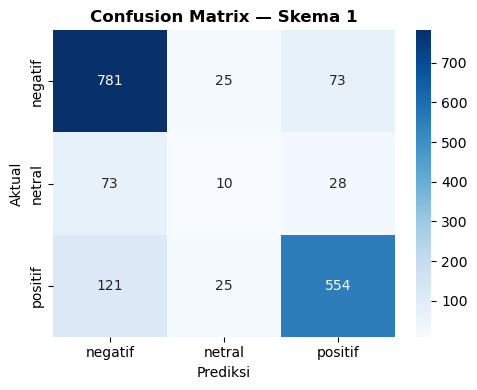

In [10]:
X_tr1, X_te1, y_tr1, y_te1 = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Train: {len(X_tr1):,} | Test: {len(X_te1):,}")

vec1 = TfidfVectorizer(ngram_range=(1,3), max_features=20000,
                        min_df=2, max_df=0.95, sublinear_tf=True)
Xtr1 = vec1.fit_transform(X_tr1).toarray()
Xte1 = vec1.transform(X_te1).toarray()
print(f"Dimensi fitur: {Xtr1.shape[1]}")

smote = SMOTE(random_state=42)
Xtr1_res, ytr1_res = smote.fit_resample(Xtr1, y_tr1)
print(f"Setelah SMOTE — Train: {len(Xtr1_res):,}")

mlp1 = MLPClassifier(hidden_layer_sizes=(512,256,128), activation='relu',
                      solver='adam', alpha=0.001, learning_rate='adaptive',
                      max_iter=300, random_state=42,
                      early_stopping=True, validation_fraction=0.1, n_iter_no_change=15)

t0 = time.time()
mlp1.fit(Xtr1_res, ytr1_res)
dur1 = time.time() - t0

tr_acc1 = accuracy_score(ytr1_res, mlp1.predict(Xtr1_res))
te_acc1 = accuracy_score(y_te1,    mlp1.predict(Xte1))
f1_1    = f1_score(y_te1,          mlp1.predict(Xte1), average='weighted')

print(f"\n{'='*45}")
print(f" SKEMA 1")
print(f"{'='*45}")
print(f" Train Accuracy : {tr_acc1*100:.2f}%")
print(f" Test Accuracy  : {te_acc1*100:.2f}%")
print(f" F1-Score       : {f1_1*100:.2f}%")
print(f" Waktu          : {dur1:.1f}s | Iterasi: {mlp1.n_iter_}")
print(f"{'='*45}")
print(classification_report(y_te1, mlp1.predict(Xte1), target_names=le.classes_))

plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_te1, mlp1.predict(Xte1)), annot=True, fmt='d',
            cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix — Skema 1', fontweight='bold')
plt.ylabel('Aktual'); plt.xlabel('Prediksi')
plt.tight_layout(); plt.savefig('cm_skema1.png', dpi=150); plt.show()

Skema 2 — Deep MLP + TF-IDF



Train: 6,757 | Test: 1,690
Dimensi fitur: 20000
Setelah SMOTE — Train: 10,548

 SKEMA 2
 Train Accuracy : 98.32%
 Test Accuracy  : 79.47%
 F1-Score       : 78.83%
 Waktu          : 1002.8s | Iterasi: 20
              precision    recall  f1-score   support

     negatif       0.81      0.86      0.83       879
      netral       0.22      0.15      0.18       111
     positif       0.83      0.82      0.83       700

    accuracy                           0.79      1690
   macro avg       0.62      0.61      0.61      1690
weighted avg       0.78      0.79      0.79      1690



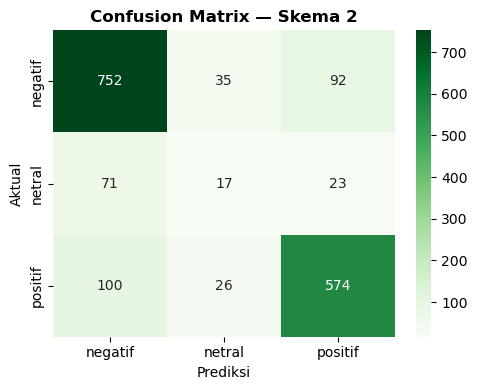

In [11]:
X_tr2, X_te2, y_tr2, y_te2 = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
print(f"Train: {len(X_tr2):,} | Test: {len(X_te2):,}")

vec2 = TfidfVectorizer(analyzer='char_wb', ngram_range=(3,5),
                        max_features=20000, sublinear_tf=True)
Xtr2 = vec2.fit_transform(X_tr2).toarray()
Xte2 = vec2.transform(X_te2).toarray()
print(f"Dimensi fitur: {Xtr2.shape[1]}")

smote = SMOTE(random_state=42)
Xtr2_res, ytr2_res = smote.fit_resample(Xtr2, y_tr2)
print(f"Setelah SMOTE — Train: {len(Xtr2_res):,}")

mlp2 = MLPClassifier(hidden_layer_sizes=(512,256,128,64), activation='relu',
                      solver='adam', alpha=0.0005, learning_rate='adaptive',
                      learning_rate_init=0.001, max_iter=300,
                      random_state=42, early_stopping=True,
                      validation_fraction=0.1, n_iter_no_change=15, batch_size=64)

t0 = time.time()
mlp2.fit(Xtr2_res, ytr2_res)
dur2 = time.time() - t0

tr_acc2 = accuracy_score(ytr2_res, mlp2.predict(Xtr2_res))
te_acc2 = accuracy_score(y_te2,    mlp2.predict(Xte2))
f1_2    = f1_score(y_te2,          mlp2.predict(Xte2), average='weighted')

print(f"\n{'='*45}")
print(f" SKEMA 2")
print(f"{'='*45}")
print(f" Train Accuracy : {tr_acc2*100:.2f}%")
print(f" Test Accuracy  : {te_acc2*100:.2f}%")
print(f" F1-Score       : {f1_2*100:.2f}%")
print(f" Waktu          : {dur2:.1f}s | Iterasi: {mlp2.n_iter_}")
print(f"{'='*45}")
print(classification_report(y_te2, mlp2.predict(Xte2), target_names=le.classes_))

plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_te2, mlp2.predict(Xte2)), annot=True, fmt='d',
            cmap='Greens', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix — Skema 2', fontweight='bold')
plt.ylabel('Aktual'); plt.xlabel('Prediksi')
plt.tight_layout(); plt.savefig('cm_skema2.png', dpi=150); plt.show()

 Skema 3 — MLP + TF-IDF


Train: 5,912 | Test: 2,535
Dimensi fitur: 11372
Setelah SMOTE — Train: 9,228

 SKEMA 3
 Train Accuracy : 92.54%
 Test Accuracy  : 81.10%
 F1-Score       : 80.24%
 Waktu          : 124.6s | Iterasi: 17
              precision    recall  f1-score   support

     negatif       0.82      0.89      0.85      1319
      netral       0.15      0.10      0.12       166
     positif       0.86      0.83      0.85      1050

    accuracy                           0.81      2535
   macro avg       0.61      0.60      0.61      2535
weighted avg       0.80      0.81      0.80      2535



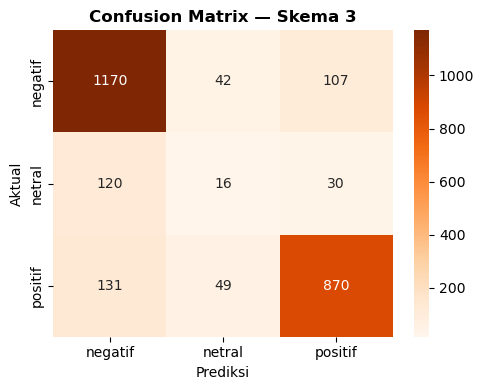

In [12]:
X_tr3, X_te3, y_tr3, y_te3 = train_test_split(X, y, test_size=0.3, random_state=7, stratify=y)
print(f"Train: {len(X_tr3):,} | Test: {len(X_te3):,}")

vec3 = TfidfVectorizer(ngram_range=(1,3), max_features=20000,
                        min_df=2, sublinear_tf=True)
Xtr3 = vec3.fit_transform(X_tr3).toarray()
Xte3 = vec3.transform(X_te3).toarray()
print(f"Dimensi fitur: {Xtr3.shape[1]}")

smote = SMOTE(random_state=42)
Xtr3_res, ytr3_res = smote.fit_resample(Xtr3, y_tr3)
print(f"Setelah SMOTE — Train: {len(Xtr3_res):,}")

mlp3 = MLPClassifier(hidden_layer_sizes=(384,192,96), activation='tanh',
                      solver='adam', alpha=0.001, learning_rate='adaptive',
                      max_iter=300, random_state=42,
                      early_stopping=True, validation_fraction=0.1, n_iter_no_change=15)

t0 = time.time()
mlp3.fit(Xtr3_res, ytr3_res)
dur3 = time.time() - t0

tr_acc3 = accuracy_score(ytr3_res, mlp3.predict(Xtr3_res))
te_acc3 = accuracy_score(y_te3,    mlp3.predict(Xte3))
f1_3    = f1_score(y_te3,          mlp3.predict(Xte3), average='weighted')

print(f"\n{'='*45}")
print(f" SKEMA 3")
print(f"{'='*45}")
print(f" Train Accuracy : {tr_acc3*100:.2f}%")
print(f" Test Accuracy  : {te_acc3*100:.2f}%")
print(f" F1-Score       : {f1_3*100:.2f}%")
print(f" Waktu          : {dur3:.1f}s | Iterasi: {mlp3.n_iter_}")
print(f"{'='*45}")
print(classification_report(y_te3, mlp3.predict(Xte3), target_names=le.classes_))

plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_te3, mlp3.predict(Xte3)), annot=True, fmt='d',
            cmap='Oranges', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix — Skema 3', fontweight='bold')
plt.ylabel('Aktual'); plt.xlabel('Prediksi')
plt.tight_layout(); plt.savefig('cm_skema3.png', dpi=150); plt.show()

PERBANDINGAN SEMUA 
  Skema                      Algoritma                 Fitur Split  Train Acc %  Test Acc %  F1-Score %
Skema 1         MLP (512-256-128) ReLU TF-IDF Word (1-3gram) 80/20        97.15       79.59       78.46
Skema 2 Deep MLP (512-256-128-64) ReLU TF-IDF Char (3-5gram) 80/20        98.32       79.47       78.83
Skema 3          MLP (384-192-96) Tanh TF-IDF Word (1-3gram) 70/30        92.54       81.10       80.24


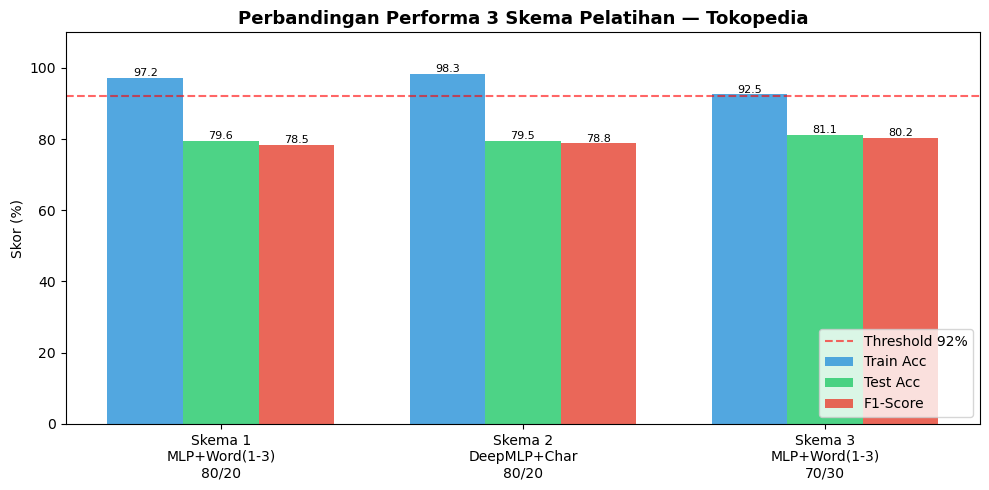

In [16]:
summary = pd.DataFrame({
    'Skema'       : ['Skema 1','Skema 2','Skema 3'],
    'Algoritma'   : ['MLP (512-256-128) ReLU','Deep MLP (512-256-128-64) ReLU','MLP (384-192-96) Tanh'],
    'Fitur'       : ['TF-IDF Word (1-3gram)','TF-IDF Char (3-5gram)','TF-IDF Word (1-3gram)'],
    'Split'       : ['80/20','80/20','70/30'],
    'Train Acc %' : [round(tr_acc1*100,2), round(tr_acc2*100,2), round(tr_acc3*100,2)],
    'Test Acc %'  : [round(te_acc1*100,2), round(te_acc2*100,2), round(te_acc3*100,2)],
    'F1-Score %'  : [round(f1_1*100,2),    round(f1_2*100,2),    round(f1_3*100,2)],
})
print("PERBANDINGAN SEMUA ")
print("="*90)
print(summary.to_string(index=False))
print("="*90)

fig, ax = plt.subplots(figsize=(10,5))
x = np.arange(3); w = 0.25
ax.bar(x-w, summary['Train Acc %'], w, label='Train Acc', color='#3498db', alpha=0.85)
ax.bar(x,   summary['Test Acc %'],  w, label='Test Acc',  color='#2ecc71', alpha=0.85)
ax.bar(x+w, summary['F1-Score %'],  w, label='F1-Score',  color='#e74c3c', alpha=0.85)
ax.axhline(92, color='red', linestyle='--', alpha=0.6, label='Threshold 92%')
ax.set_xticks(x)
ax.set_xticklabels(['Skema 1\nMLP+Word(1-3)\n80/20',
                    'Skema 2\nDeepMLP+Char\n80/20',
                    'Skema 3\nMLP+Word(1-3)\n70/30'], fontsize=10)
ax.set_ylabel('Skor (%)'); ax.set_ylim(0, 110)
ax.set_title('Perbandingan Performa 3 Skema Pelatihan — Tokopedia',
             fontweight='bold', fontsize=13)
ax.legend(loc='lower right')
for i,(tr,te,f1) in enumerate(zip(summary['Train Acc %'],summary['Test Acc %'],summary['F1-Score %'])):
    ax.text(i-w, tr+0.5, f'{tr:.1f}', ha='center', fontsize=8)
    ax.text(i,   te+0.5, f'{te:.1f}', ha='center', fontsize=8)
    ax.text(i+w, f1+0.5, f'{f1:.1f}', ha='center', fontsize=8)
plt.tight_layout()
plt.show()


# **cell inference**

In [15]:
def predict(texts, model=mlp1, vectorizer=vec1):
    if isinstance(texts, str):
        texts = [texts]
    clean = [preprocess(t) for t in texts]
    vecs  = vectorizer.transform(clean).toarray()
    preds = model.predict(vecs)
    proba = model.predict_proba(vecs)
    return [
        {'teks': t, 'sentimen': le.inverse_transform([p])[0], 'confidence': f'{max(pr)*100:.1f}%'}
        for t, p, pr in zip(texts, preds, proba)
    ]

test_teks = [
    "Aplikasi Tokopedia sangat membantu, belanja jadi mudah dan cepat!",
    "Banyak promo menarik, cashback setiap hari, recommended banget",
    "Aplikasi sering error dan lambat, sangat mengecewakan",
    "Barang tidak sesuai foto, penjual tidak mau refund sama sekali",
    "Biasa aja sih, sama seperti aplikasi belanja lainnya",
    "Lumayan oke tapi ada beberapa bug yang mengganggu",
    "Flash sale susah checkout, server selalu down pas promo",
    "Pengiriman cepat, packaging aman, produk original terjamin",
    "Customer service tidak responsif, komplain diabaikan terus",
    "Cukup membantu untuk kebutuhan belanja sehari-hari",
]

hasil = predict(test_teks)
emoji_map = {'positif':'✅', 'negatif':'❌', 'netral':'⚪'}

print("HASIL INFERENSI ANALISIS SENTIMEN — TOKOPEDIA")
print("="*75)
print(f"{'No':<4} {'Sentimen':<12} {'Keyakinan':<12} {'Teks'}")
print("-"*75)
for i, row in enumerate(hasil):
    e = emoji_map.get(row['sentimen'], '')
    print(f"{i+1:<4} {e} {row['sentimen']:<10} {row['confidence']:<12} {row['teks'][:50]}...")

print("\nRingkasan:")
from collections import Counter
print(Counter(r['sentimen'] for r in hasil))


HASIL INFERENSI ANALISIS SENTIMEN — TOKOPEDIA
No   Sentimen     Keyakinan    Teks
---------------------------------------------------------------------------
1    ✅ positif    100.0%       Aplikasi Tokopedia sangat membantu, belanja jadi m...
2    ✅ positif    98.7%        Banyak promo menarik, cashback setiap hari, recomm...
3    ⚪ netral     95.0%        Aplikasi sering error dan lambat, sangat mengecewa...
4    ❌ negatif    96.2%        Barang tidak sesuai foto, penjual tidak mau refund...
5    ✅ positif    97.8%        Biasa aja sih, sama seperti aplikasi belanja lainn...
6    ✅ positif    95.3%        Lumayan oke tapi ada beberapa bug yang mengganggu...
7    ❌ negatif    88.6%        Flash sale susah checkout, server selalu down pas ...
8    ✅ positif    98.9%        Pengiriman cepat, packaging aman, produk original ...
9    ❌ negatif    98.8%        Customer service tidak responsif, komplain diabaik...
10   ✅ positif    99.9%        Cukup membantu untuk kebutuhan belanja sehari-h

In [13]:
bundle = {'model': mlp1, 'vectorizer': vec1, 'label_encoder': le}
with open('model_tokopedia_sentimen.pkl', 'wb') as f:
    pickle.dump(bundle, f)

print(" Model tersimpan: model_tokopedia_sentimen.pkl")



 Model tersimpan: model_tokopedia_sentimen.pkl
